In [29]:
import torchxrayvision as xrv
import torch, torchvision
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt

# Projection algorithms
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, Isomap
import umap.umap_ as umap
import pacmap

### Constants and Configs

In [30]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Fixed seed for reproducibility
RANDOM_STATE = 42

In [31]:
PATHOLOGIES = [
    "Lung Opacity",
    "Fracture",
    # TODO: check if we should add this or not
    #"Nodule/Mass",
    "Pneumothorax"
]

### Load and Prepare

In [32]:
def load_dataset(image_path: str = "./nih_data_small", datasetClass = xrv.datasets.NIH_Google_Dataset):
    transform = torchvision.transforms.Compose([xrv.datasets.XRayCenterCrop(),xrv.datasets.XRayResizer(224)])
    d_nih = datasetClass(imgpath=image_path, transform=transform, views=["PA", "AP"])
    print(f'found {len(d_nih)} images')
    return d_nih

In [33]:
NIH_GOOGLE_DATASET = load_dataset()
DATASET_PATHOLOGIES = list(NIH_GOOGLE_DATASET.pathologies)
DATASET_LABEL_INDICES = {
        name: DATASET_PATHOLOGIES.index(name)
        for name in PATHOLOGIES
}
DATASET_INDICES_LABEL = {DATASET_LABEL_INDICES[l]:l for l in DATASET_LABEL_INDICES}

found 1695 images


In [34]:
DATASET_INDICES_LABEL

{0: 'Lung Opacity', 1: 'Fracture', 3: 'Pneumothorax'}

In [35]:
def create_image_feature_space_and_label(dataset, dataset_indices_label = DATASET_INDICES_LABEL):
    image_features_list = []
    labels_list = []
    for i in range(len(dataset)):
        sample = dataset[i]
        label = np.asarray(sample["lab"]).reshape(-1)

        img = np.asarray(sample["img"]).squeeze()
        image_features_list.append(
                        img.astype(np.float32).reshape(-1)
            )
            
        labels_list.append(
                    label
                )

    image_features = np.stack(
        image_features_list,
        axis=0
    )
    labels = np.array(labels_list)
    return image_features, labels


In [36]:
NIH_GOOGLE_IMAGE_FEATURES, NIH_GOOGLE_LABELS_LIST = create_image_feature_space_and_label(NIH_GOOGLE_DATASET)

### Load model

In [37]:
def load_model(model_weights: str = "densenet121-res224-chex"):
    model = xrv.models.DenseNet(weights=model_weights)
    model.eval()
    return model.to(DEVICE)

In [38]:
DENSENET121_RES244_CHEX_MODEL = load_model()
DENSENET121_RES244_CHEX_MODEL.eval()

XRV-DenseNet121-densenet121-res224-chex

In [39]:
def get_model_to_dataset_indices(model = DENSENET121_RES244_CHEX_MODEL, dataset_label_indices=DATASET_LABEL_INDICES):
    return {
        model_idx: dataset_label_indices[pathology]
        for model_idx, pathology in enumerate(model.pathologies)
        if pathology in dataset_label_indices
    }   

In [76]:
MODEL_TO_DATASET_INDICES = get_model_to_dataset_indices()
DATASET_TO_MODEL_INDICES = {MODEL_TO_DATASET_INDICES[key]:key for key in MODEL_TO_DATASET_INDICES}
print(MODEL_TO_DATASET_INDICES)
print(DATASET_TO_MODEL_INDICES)

{3: 3, 15: 1, 16: 0}
{3: 3, 1: 15, 0: 16}


### Prediction of the model

In [41]:
DATASET_LABEL_INDICES

{'Lung Opacity': 0, 'Fracture': 1, 'Pneumothorax': 3}

In [57]:
def calculate_model_predictions_score(
    feature_space,
    model,
    batch_size=32
):
    model.eval()

    # Convert flattened images to (N, 1, 224, 224)
    images = torch.as_tensor(feature_space, dtype=torch.float32)
    images = images.reshape(-1, 1, 224, 224)

    # Run inference in batches
    all_outputs = []

    with torch.no_grad():
        for start_idx in range(0, len(images), batch_size):
            end_idx = start_idx + batch_size

            batch = images[start_idx:end_idx].to(DEVICE)

            batch_outputs = model(batch)

            # Move each batch back to CPU immediately
            batch_outputs = batch_outputs.cpu().numpy()


            all_outputs.append(batch_outputs)

    # Combine all batches
    selected_outputs = np.concatenate(all_outputs, axis=0)
    return selected_outputs

In [58]:
MODEL_SCORE_PREDICTIONS = calculate_model_predictions_score(NIH_GOOGLE_IMAGE_FEATURES,
                                                       DENSENET121_RES244_CHEX_MODEL)

### Downprojection

In [44]:
class Downprojector:

    def __init__(self, image_features):
        self.projection_cache = {}
        self.image_features = image_features


    def get_feature_matrix(self, feature_space):
        return self.image_features

    """
    PCA is used as a preprocessing step for the non-linear
        projection techniques.
    """
    def prepare_pca_features(self, feature_space):
        cache_key = f"{feature_space}_pca"
         
        if cache_key in self.projection_cache:
            return self.projection_cache[cache_key]
         
        X = self.get_feature_matrix(feature_space)
         
             # Keep at most 50 dimensions before expensive
             # non-linear dimensionality reduction.
        n_components = min(
                 50,
                 X.shape[0],
                 X.shape[1]
             )
         
        pca = PCA(
                 n_components=n_components,
                 random_state=RANDOM_STATE
        )
         
        X_pca = pca.fit_transform(X)
         
        self.projection_cache[cache_key] = {
                 "data": X_pca,
                 "pca": pca
             }
         
        return self.projection_cache[cache_key]

    def calculate_projection(self, feature_space: str, method: str):
        cache_key = (
                f"{feature_space}_{method}"
            )
        
        if cache_key in self.projection_cache:
            return self.projection_cache[cache_key]


        if method == "PCA":

            X = self.get_feature_matrix(feature_space)

            reducer = PCA(
                n_components=2,
                random_state=RANDOM_STATE
            )

            embedding = reducer.fit_transform(X)
        elif method == "t-SNE":
        
            X_pca = self.prepare_pca_features(
                    feature_space
                )["data"]
        
                # t-SNE requires perplexity < number of samples.
            perplexity = min(
                    30,
                    max(5, (X_pca.shape[0] - 1) // 3)
                )
        
            reducer = TSNE(
                    n_components=2,
                    perplexity=perplexity,
                    init="pca",
                    learning_rate="auto",
                    random_state=RANDOM_STATE
                )
        
            embedding = reducer.fit_transform(
                    X_pca
                )
        elif method == "UMAP":
            X_pca = self.prepare_pca_features(
                    feature_space
                )["data"]

            n_neighbors = min(
                    15,
                    max(2, X_pca.shape[0] - 1)
                )

            reducer = umap.UMAP(
                    n_components=2,
                    n_neighbors=n_neighbors,
                    min_dist=0.1,
                    metric="euclidean",
                    random_state=RANDOM_STATE
                )

            embedding = reducer.fit_transform(
                    X_pca
                )
        else:
            raise ValueError(
                f"Unknown projection method: {method}"
                )
        self.projection_cache[cache_key] = embedding
        return embedding

### Run first visualization

In [45]:
def visualize_space(feature_space, projection_method,
                    label_name="Pneumothorax",
                     labels_list=NIH_GOOGLE_LABELS_LIST,
                     dataset_label_indices = DATASET_LABEL_INDICES):
    label_index = dataset_label_indices[label_name]
    label_pathologie_label_output = labels_list[:, label_index]
    idx_pathologie = label_pathologie_label_output == 1
    idx_non_pathologie = label_pathologie_label_output == 0

    plt.scatter(feature_space[idx_pathologie,0], feature_space[idx_pathologie,1], label=label_name, c='red')
    plt.scatter(feature_space[idx_non_pathologie,0], feature_space[idx_non_pathologie,1], label='Not effected', c='blue',
                alpha=0.1)

    plt.title(f"{projection_method} Projection Colored")
    plt.xlabel(f"{projection_method} 1")
    plt.ylabel(f"{projection_method} 2")
    plt.legend()
    plt.show()

In [46]:
downprojector = Downprojector(NIH_GOOGLE_IMAGE_FEATURES)

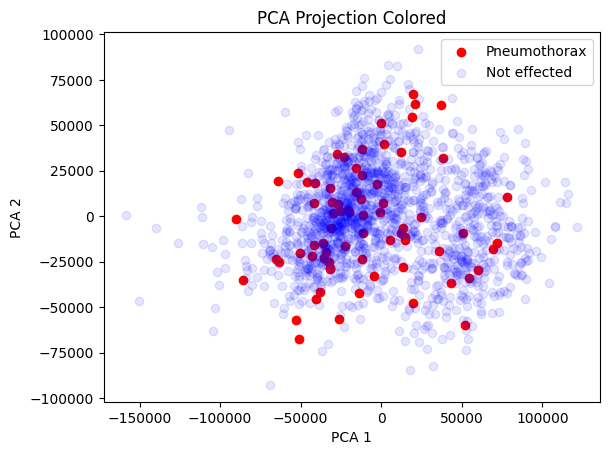

In [47]:
X_pca = downprojector.calculate_projection('NIH_Google_Dataset', 'PCA')
visualize_space(X_pca, 'PCA')


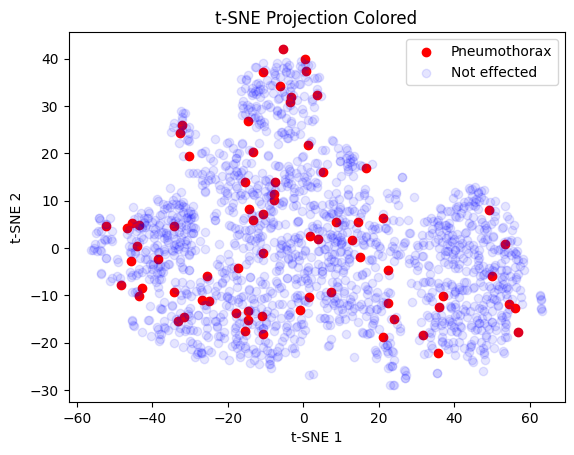

In [69]:
X_tsne = downprojector.calculate_projection('NIH_Google_Dataset', 't-SNE')
visualize_space(X_tsne, 't-SNE')

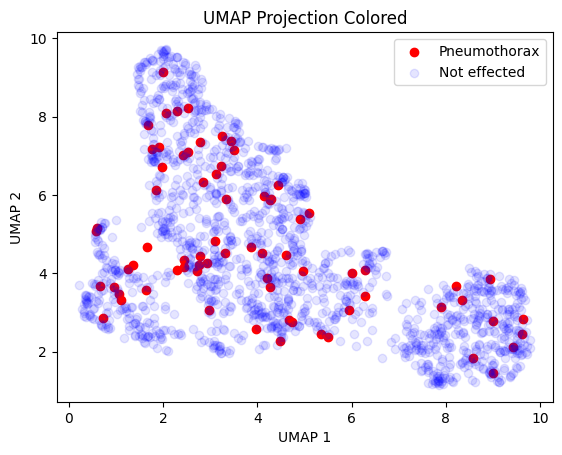

In [49]:
X_umap = downprojector.calculate_projection('NIH_Google_Dataset', 'UMAP')
visualize_space(X_umap, 'UMAP')

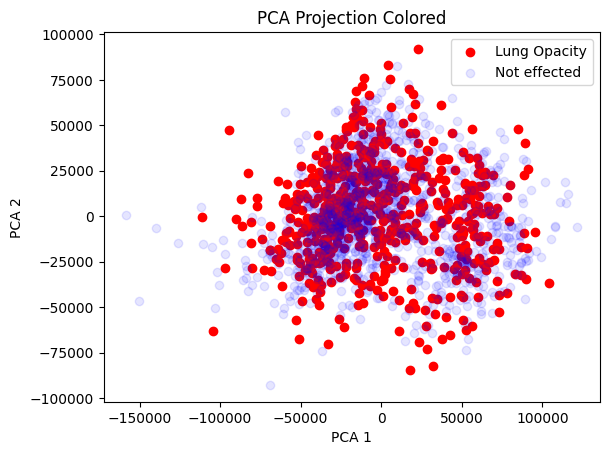

In [68]:
visualize_space(X_pca, 'PCA', "Lung Opacity")

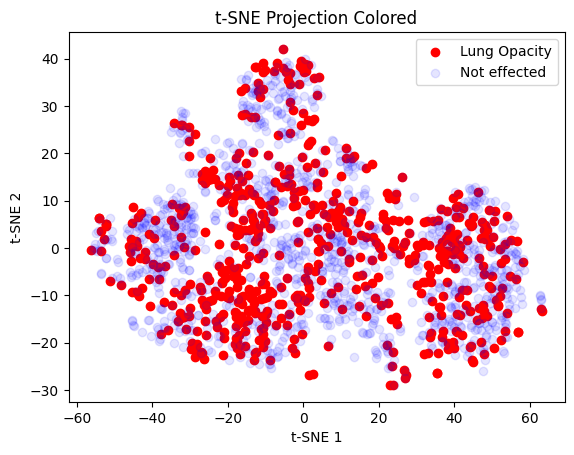

In [70]:
visualize_space(X_tsne, 't-SNE', "Lung Opacity")

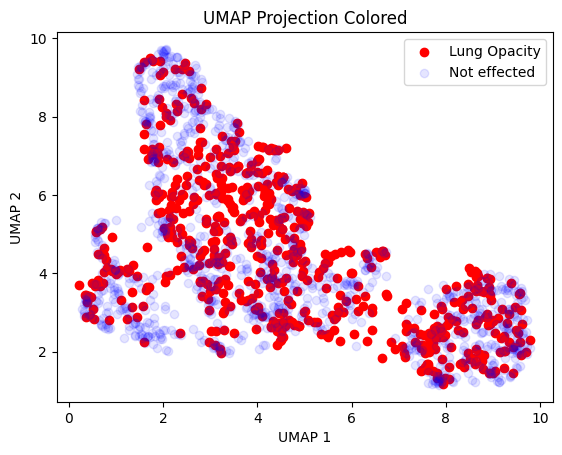

In [67]:
visualize_space(X_umap, 'UMAP', "Lung Opacity")

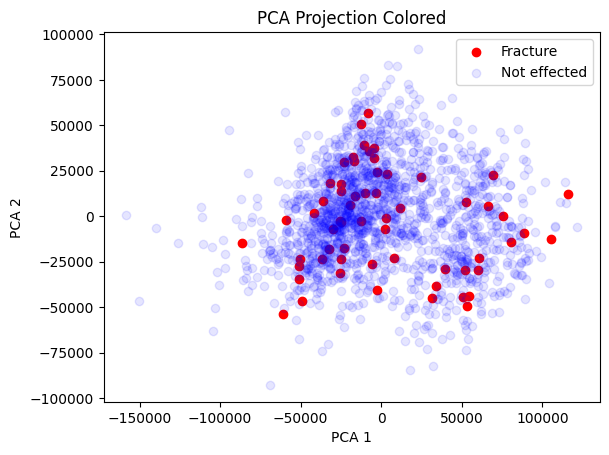

In [81]:
visualize_space(X_pca, 'PCA', "Fracture")

### Visualize predictions


In [74]:
DATASET_LABEL_INDICES

{'Lung Opacity': 0, 'Fracture': 1, 'Pneumothorax': 3}

In [75]:
MODEL_TO_DATASET_INDICES

{3: 3, 15: 1, 16: 0}

In [77]:
def visualize_space_prediction_scores(feature_space, projection_method, predictions,
                    label_name="Pneumothorax", dataset_label_indices = DATASET_LABEL_INDICES,
                    dataset_to_model_indices=DATASET_TO_MODEL_INDICES):

    # Find the prediction column for this finding
    dataset_label_index = dataset_label_indices[label_name]
   
    model_label_index = dataset_to_model_indices[dataset_label_index]

    # Get the model score for each image
    scores = predictions[:, model_label_index]

    plt.figure(figsize=(10, 7))

    scatter = plt.scatter(
        feature_space[:, 0],
        feature_space[:, 1],
        c=scores,
        cmap="viridis",
        alpha=0.8,
        s=20
    )

    plt.colorbar(scatter, label=f"Model score: {label_name}")
    plt.title(f"{projection_method} Projection Colored by {label_name} Score")
    plt.xlabel(f"{projection_method} 1")
    plt.ylabel(f"{projection_method} 2")
    plt.show()

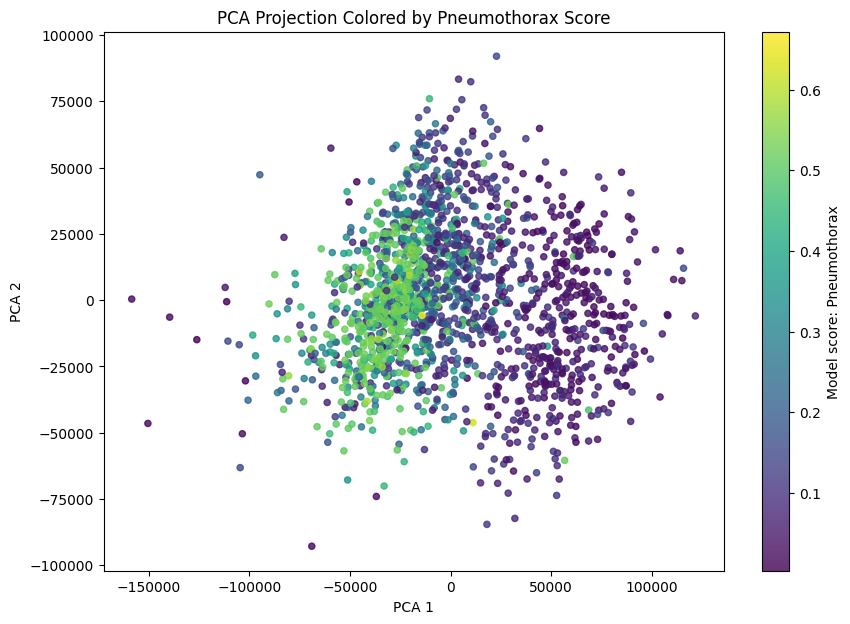

In [78]:
visualize_space_prediction_scores(X_pca, 'PCA', MODEL_SCORE_PREDICTIONS)

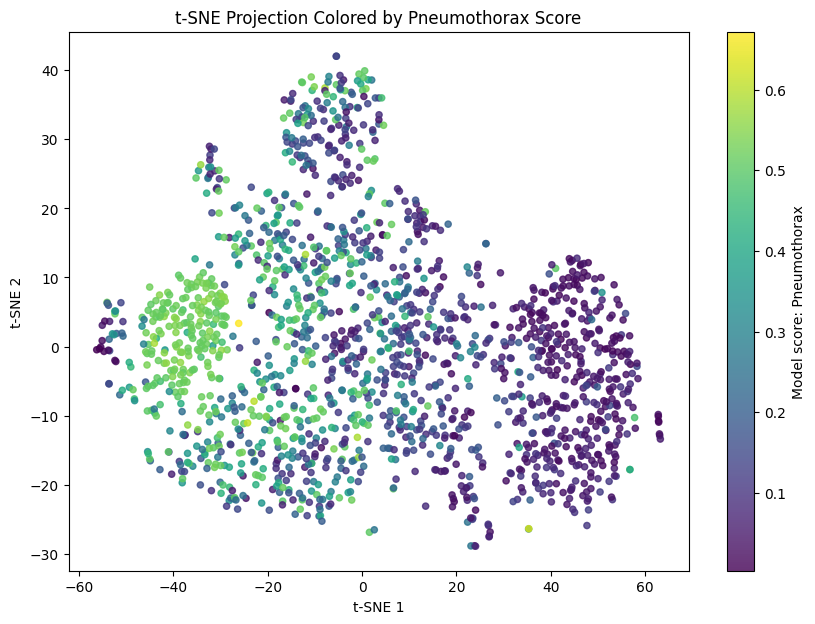

In [71]:
visualize_space_prediction_scores(X_tsne, 't-SNE', MODEL_SCORE_PREDICTIONS)

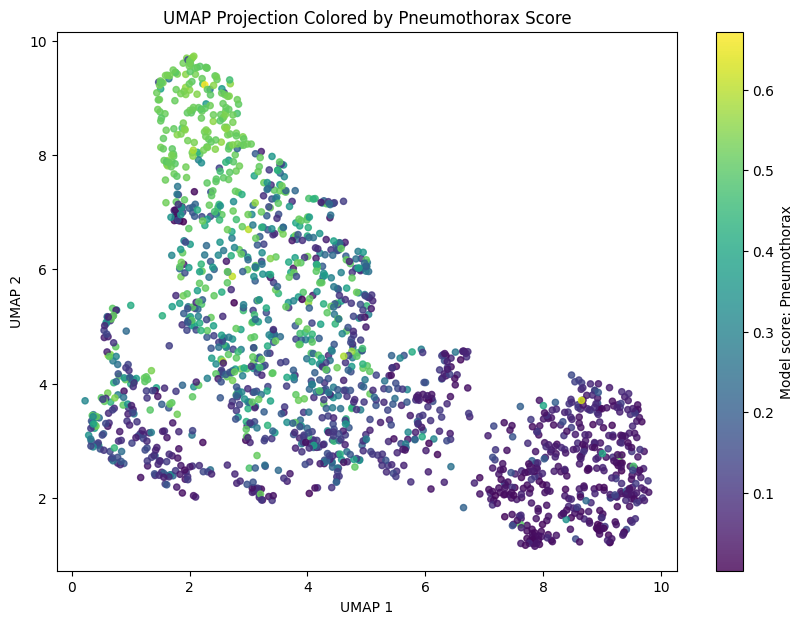

In [66]:
visualize_space_prediction_scores(X_umap, 'UMAP', MODEL_SCORE_PREDICTIONS)

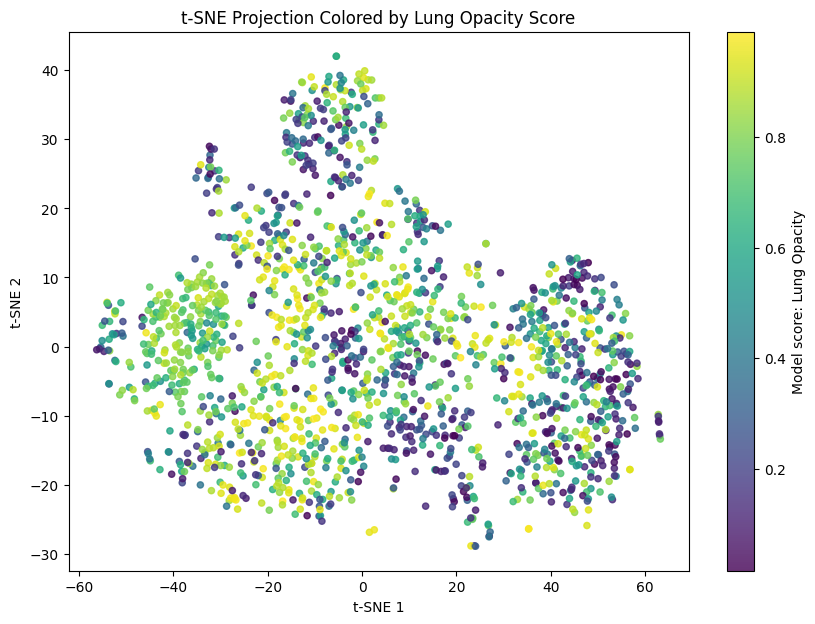

In [79]:
visualize_space_prediction_scores(X_tsne, 't-SNE', MODEL_SCORE_PREDICTIONS, "Lung Opacity")

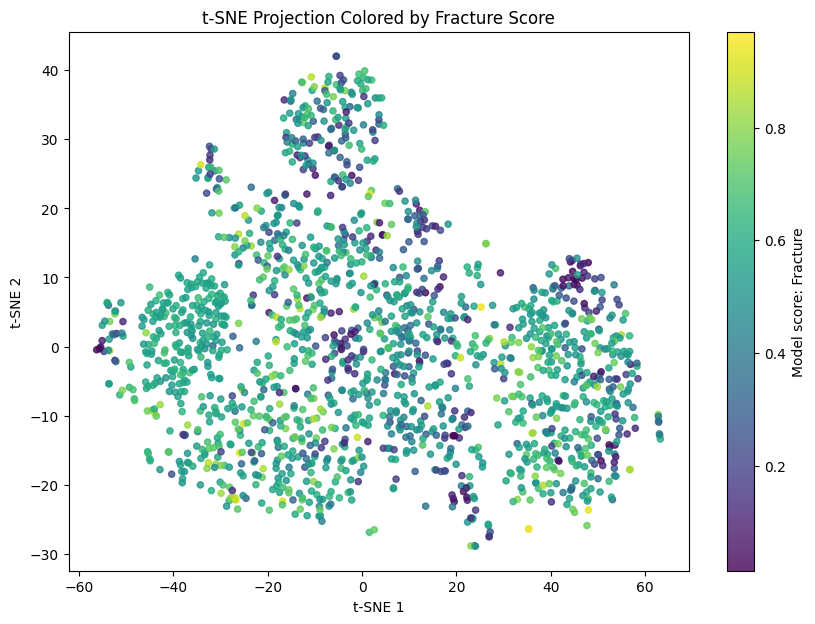

In [80]:
visualize_space_prediction_scores(X_tsne, 't-SNE', MODEL_SCORE_PREDICTIONS, "Fracture")